# Clustering

*Session 11, block 1. Course material, licence CC BY 4.0. Sections marked "adapted from" reuse third-party material under the licence named there.*

Until now every model in the course had a target: a price, a churn flag, a busy listing. This block works without one. After it you can explain how unsupervised learning differs from supervised learning and why it is harder to evaluate, you can run k-means by hand and in scikit-learn, and you can apply and evaluate k-means, hierarchical clustering and DBSCAN on real data: the Telco customers (without the churn label) and the Berlin Airbnb listings.

## Overview

| Section | What it covers |
|---|---|
| Supervised and unsupervised learning | targets and labels, clustering, dimensionality reduction and anomaly detection, three kinds of evidence instead of a test score, clusters in pure noise |
| Distance, similarity and scaling | Euclidean, Manhattan, cosine and correlation distance, the three metrics side by side, why units decide the result, standardising, scaling and nearest neighbours |
| k-means | assign and update steps, inertia, k-means by hand and in scikit-learn, k-means++ and `n_init`, expectation–maximisation, where k-means fails, Gaussian mixtures, digits and colour compression |
| Choosing the number of clusters: elbow and silhouette | the elbow method, the silhouette, both on the Telco customers, a segment profile, silhouette plots |
| From customers to listings | the Berlin listings as six standardised features |
| Hierarchical clustering and dendrograms | agglomerative clustering, linkages, dendrograms, linkages compared on toy data, Ward on the listings, a dendrogram from scikit-learn |
| Density-based clustering (DBSCAN) | core, border and noise points, external metrics with known labels, the k-distance plot, hot spots on the map, DBSCAN on the listing features, HDBSCAN, all methods on toy data |
| Evaluating and interpreting clusters | separation, bootstrap stability, the adjusted Rand index |
| Worked example · What kinds of Airbnb offers exist in Berlin? | cluster profiles on the original scale, districts as outside evidence, five offer types |
| Check your understanding, Exercises, Debrief | five multiple-choice questions, eleven exercises in pairs (including a Parsons and a Find the bug exercise), what to compare afterwards |
| Further reading | textbooks, the scikit-learn user guide, the original papers and the extras of this block |

The first code cell moves to the repository root, where the case-study paths start. Run the cells in order. The Airbnb data must exist in `case-study/data/airbnb/` (download `airbnb-v1.zip` from the course drive and unzip it into `case-study/data/`; see [case-study/README.md](../../../case-study/README.md)); the Telco data are read from GitHub.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we import the main libraries of the block. `KMeans`, `AgglomerativeClustering` and `DBSCAN` are the three clustering methods; `silhouette_score` and `adjusted_rand_score` evaluate them. Later sections import what else they need where they use it.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 12)
plt.rcParams["figure.dpi"] = 72                                # keeps the saved notebook small

## Supervised and unsupervised learning

In **supervised learning** every training row has inputs X and a known answer y, the **target** or **label**. The model learns to map X to y, and we can count how often it is right on new rows. In **unsupervised learning** there is only X. The task is to describe the structure of X:

- **clustering**: groups of similar rows (this block);
- **dimensionality reduction**: a few new columns that summarise many (block 2);
- **anomaly detection**: rows that do not fit the rest (block 2).

An everyday analogy: sorting a drawer of mixed screws without a catalogue. You can group them by length and head type, but nobody can tell you the "right" grouping. Two people may sort differently and both be reasonable.

That is the core difficulty: **without y there is no test score**. We judge a clustering with three kinds of evidence instead:

1. **Internal criteria**, computed from X and the clusters alone (inertia, silhouette).
2. **Stability**: do we get the same clusters on a slightly different sample, or with a different random start?
3. **Usefulness**: can people describe the groups, and do the groups help a decision or a later model?

```mermaid
flowchart LR
    Q{"Is there a target y<br/>in the training data?"} -->|yes| S["Supervised:<br/>regression, classification"]
    Q -->|no| U["Unsupervised:<br/>clusters, components, anomalies"]
    S --> SE["Evaluate against y<br/>on a test set"]
    U --> UE["Evaluate with internal criteria,<br/>stability and usefulness"]
```

Where clustering is used in practice: customer and market segmentation; geodemographic area classifications such as the UK Office for National Statistics' Output Area Classification, built with k-means on census variables; disease subtypes found in gene-expression data and only later checked against outcomes (Perou et al., 2000); grouping documents or support tickets before anyone has labelled them.

Our first data are the Telco customers of Sessions 6 and 8. We keep three numeric columns as X and put the churn label aside: it may *describe* clusters afterwards, but it must not *build* them. `pd.to_numeric(..., errors="coerce")` turns the blank total charges of brand-new customers into `NaN`.

In [3]:
url = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
telco = pd.read_csv(url)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")
telco = telco.dropna(subset=["TotalCharges"]).reset_index(drop=True)

X = telco[["tenure", "MonthlyCharges", "TotalCharges"]]   # the only input of the clustering
print(X.shape)
X.describe().loc[["mean", "std", "min", "max"]].round(1)

(7032, 3)


,tenure,MonthlyCharges,TotalCharges
mean,32.4,64.8,2283.3
std,24.5,30.1,2266.8
min,1.0,18.2,18.8
max,72.0,118.8,8684.8


**Predict.** We now give k-means 2,000 points drawn *uniformly at random* in a square, so there are no groups at all, and ask for four clusters. What will it return? Note the API: `KMeans(...).fit(X)` takes no y, and `fit_predict` returns the cluster number of every row.

In [4]:
noise = np.random.default_rng(0).uniform(size=(2000, 2))
labels = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(noise)
pd.Series(labels).value_counts().sort_index()

0    532
1    504
2    492
3    472
Name: count, dtype: int64

Four tidy groups of about 500 points, from pure noise. **A clustering always returns clusters.** Whether the groups exist is a question for the evaluation, not for the algorithm.

> **Note.** Do not cluster on the target. If churn were part of X, the "segments" would partly reproduce churn and look more useful than they are. Keep the label out and use it only to describe the result.

## Distance, similarity and scaling

Clustering groups rows that are "close". Closeness is a **distance** (small means similar) or a **similarity** (large means similar):

- **Euclidean distance**, the straight line: square the differences per column, add them, take the square root. The default of k-means.
- **Manhattan distance**, the walk along a city grid: add the absolute differences. One large difference counts less than with Euclidean distance.
- **Cosine similarity**, the angle between two rows seen as arrows, ignoring their length. Used for texts in Sessions 13 and 14, where a long and a short text on the same topic should count as similar.
- **Correlation-based distance**, one minus the correlation between two rows: two rows are similar when their values go up and down together, whatever their level. Used for gene-expression profiles and for shopping baskets.

### Euclidean, Manhattan and cosine side by side

`sklearn.metrics.pairwise_distances(X, metric=...)` computes all pairwise distances for a chosen metric. Below, three made-up shopping baskets (euros spent on food, drinks and household goods): basket B is basket A doubled, basket C spends the same total as A in a different mix.

**Predict.** Which pair is closest under each metric?

In [5]:
from sklearn.metrics import pairwise_distances

baskets = pd.DataFrame({"food": [20, 40, 10], "drinks": [10, 20, 5], "household": [5, 10, 20]},
                       index=["A", "B (A doubled)", "C (other mix)"])
for metric in ["euclidean", "manhattan", "cosine"]:
    D = pd.DataFrame(pairwise_distances(baskets, metric=metric), index=baskets.index, columns=baskets.index)
    print(metric, "\n", D.round(2), "\n")

euclidean 
                    A  B (A doubled)  C (other mix)
A               0.00          22.91          18.71
B (A doubled)  22.91           0.00          35.00
C (other mix)  18.71          35.00           0.00 

manhattan 
                   A  B (A doubled)  C (other mix)
A               0.0           35.0           30.0
B (A doubled)  35.0            0.0           55.0
C (other mix)  30.0           55.0            0.0 

cosine 
                   A  B (A doubled)  C (other mix)
A              0.00           0.00           0.33
B (A doubled)  0.00           0.00           0.33
C (other mix)  0.33           0.33           0.00 



Euclidean and Manhattan distance call A closer to C, because the amounts are similar. Cosine distance (one minus the cosine similarity) is 0 between A and B: the same *mix*, only a larger basket. Which one is right depends on the question: "customers who spend similar amounts" or "customers who buy the same kind of things".

### Why scaling matters

Every distance-based method (k-means, hierarchical clustering, DBSCAN, nearest neighbours, PCA) inherits the **units** of the columns. Three customers make the point:

| Customer | tenure (months) | total charges ($) |
|---|---|---|
| A | 2 | 150 |
| B | 70 | 150 |
| C | 2 | 1,150 |

**Predict.** Who is A's nearest neighbour: B, who has been a customer 35 times longer, or C, who has paid $1,000 more?

Next we compute both distances, first on the raw numbers and then after **standardising** each column (subtract the mean, divide by the standard deviation of the Telco table). `np.linalg.norm(a - b)` is the Euclidean distance.

In [6]:
abc = pd.DataFrame({"tenure": [2, 70, 2], "TotalCharges": [150, 150, 1150]}, index=["A", "B", "C"])
sd = X[["tenure", "TotalCharges"]].std()
for name, table in [("raw", abc), ("standardised", abc / sd)]:
    d_ab = np.linalg.norm(table.loc["A"] - table.loc["B"])
    d_ac = np.linalg.norm(table.loc["A"] - table.loc["C"])
    print(f"{name:13s} d(A,B) = {d_ab:7.2f}   d(A,C) = {d_ac:7.2f}")

raw           d(A,B) =   68.00   d(A,C) = 1000.00
standardised  d(A,B) =    2.77   d(A,C) =    0.44


On the raw scale the dollar column decides alone, so A looks closer to B. After standardising, a difference of one standard deviation counts the same in every column and A is closer to C. (Subtracting the mean does not change differences, so dividing by the standard deviation is enough here.)

The same happens with a real clustering. Next we run k-means with three clusters on the raw columns and on the standardised ones and compare the cluster means. `StandardScaler().fit_transform(X)` standardises every column.

In [7]:
raw = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
print("raw columns: cluster means")
print(X.groupby(raw.labels_).mean().round(0))

Z_telco = StandardScaler().fit_transform(X)
scaled = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z_telco)
print("\nstandardised columns: cluster means")
print(X.groupby(scaled.labels_).mean().round(0))

raw columns: cluster means
   tenure  MonthlyCharges  TotalCharges
0    18.0            50.0         686.0
1    64.0            98.0        6293.0
2    44.0            78.0        3273.0



standardised columns: cluster means
   tenure  MonthlyCharges  TotalCharges
0    59.0            90.0        5246.0
1    30.0            27.0         812.0
2    13.0            75.0        1032.0


On the raw columns the three clusters are mostly three bands of total charges, the column with the largest numbers. After scaling, tenure and monthly charges also shape the groups.

> **Note.** Scaling is a modelling decision. Standardising gives every column equal weight; if one column should matter more, weight it on purpose and write the choice down. Strongly skewed columns (prices, counts) are usually log-transformed first, as in Session 4. For mixed numeric and categorical data, look up the Gower distance and the k-prototypes algorithm.

### Scaling changes who the neighbours are

*Adapted from [Importance of Feature Scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html) (scikit-learn developers, BSD-3-Clause).*

You met this example in Session 4 (`Why scaling matters: k-nearest neighbours and PCA`): on the wine columns proline and hue, k-nearest neighbours ignored hue until we scaled. We rerun it here only as a picture. `DecisionBoundaryDisplay.from_estimator` colours the plane by the predicted class, without and with scaling.

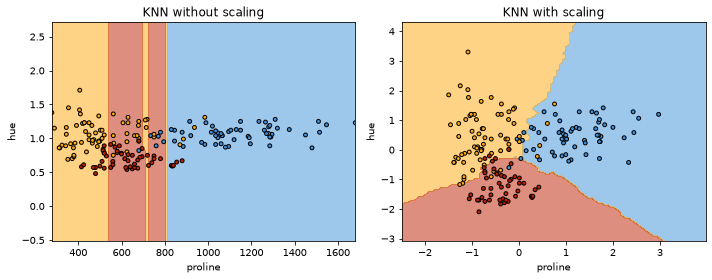

In [8]:
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_wine
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.neighbors import KNeighborsClassifier

wine_X, wine_y = load_wine(return_X_y=True, as_frame=True)
X_plot = wine_X[["proline", "hue"]]
X_plot_scaled = StandardScaler().set_output(transform="pandas").fit_transform(X_plot)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, title in [(axes[0], X_plot, "KNN without scaling"), (axes[1], X_plot_scaled, "KNN with scaling")]:
    clf = KNeighborsClassifier(n_neighbors=20).fit(data, wine_y)
    disp = DecisionBoundaryDisplay.from_estimator(clf, data, response_method="predict", alpha=0.5, ax=ax)
    ax.scatter(data["proline"], data["hue"], c=wine_y, cmap=ListedColormap(disp.multiclass_colors_), s=15, edgecolor="k")
    ax.set_title(title)
plt.tight_layout()

**What do you see?** Compare the direction of the class boundaries in the two panels.

Without scaling the boundaries are vertical bands: only proline matters. After standardising, both columns shape the neighbourhoods. What is new for this block: the same mechanism decides what k-means, hierarchical clustering and DBSCAN find, because all of them measure closeness with a distance. Scaling before PCA follows in block 2.

> 📖 **Read more:** [extras/01-feature-scaling.ipynb](extras/01-feature-scaling.ipynb) (scikit-learn gallery): the full example, including scaling before PCA and its effect on a classifier.

## k-means

**k-means** splits the rows into k clusters, each with a **centre** (the **centroid**, the mean of its rows). It repeats two steps:

1. **Assign** every row to the nearest centre.
2. **Update** every centre to the mean of its rows.

It stops when no row changes cluster. Each step lowers the **inertia**, the sum of squared distances of the rows to their own centre (also called the within-cluster sum of squares, WCSS).

Think of a town with two bakeries that may move: every household walks to the nearer one, then each bakery moves to the middle of its customers, and so on until nobody switches.

![Four panels of k-means on three groups of points: the centres start in the wrong places and move to the group means within three iterations while the inertia falls from 1275 to 212](../figures/kmeans_iterations.png)

### k-means by hand

Our hand example: the six values 1, 2, 3, 8, 9, 15, k = 2 and the deliberately poor starting centres 1 and 2.

| Iteration | Assignment | New centres |
|---|---|---|
| 1 | {1} and {2, 3, 8, 9, 15} | 1 and (2 + 3 + 8 + 9 + 15) / 5 = 7.4 |
| 2 | 2 and 3 are now closer to 1: {1, 2, 3} and {8, 9, 15} | 2 and 32 / 3 ≈ 10.67 |
| 3 | nothing changes | stop |

**Predict.** What is the inertia at the end? Compute it on paper before running the next cell.

The next cell runs the same two steps in NumPy. `x[:, None] - centres` builds a table of differences between every value and every centre (broadcasting, Session 1), and `np.argmin(..., axis=1)` picks the nearest centre per row.

In [9]:
x = np.array([1, 2, 3, 8, 9, 15], dtype=float)
centres = np.array([1.0, 2.0])                                      # deliberately poor start
for it in range(1, 10):
    labels = np.argmin(np.abs(x[:, None] - centres), axis=1)        # step 1: assign
    new = np.array([x[labels == k].mean() for k in range(2)])       # step 2: update
    print("iteration", it, "labels", labels, "centres", new.round(2))
    if np.allclose(new, centres):
        break
    centres = new
print("inertia:", round(((x - centres[labels]) ** 2).sum(), 2))

iteration 1 labels [0 1 1 1 1 1] centres [1.  7.4]
iteration 2 labels [0 0 0 1 1 1] centres [ 2.   10.67]
iteration 3 labels [0 0 0 1 1 1] centres [ 2.   10.67]
inertia: 30.67


scikit-learn should agree. `cluster_centers_` holds the centres, `inertia_` the final inertia and `labels_` the clusters; the input must be a 2-D table, hence `reshape(-1, 1)`.

In [10]:
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(x.reshape(-1, 1))
print(km.cluster_centers_.ravel().round(2), round(km.inertia_, 2), km.labels_)

[10.67  2.  ] 30.67 [1 1 1 0 0 0]


Same centres and inertia; only the cluster numbers may be swapped. **Cluster numbers are arbitrary names**: never hard-code "cluster 2 is the high-value segment"; identify clusters by their profile.

What the hand computation shows:

- k-means uses **means**, so outliers pull the centres;
- it uses the distance to **one centre**, so it prefers round clusters of similar size;
- it only finds a **local** minimum of the inertia, so the start matters. scikit-learn spreads the first centres apart (**k-means++**: each new starting centre is drawn with a probability that grows with its squared distance from the centres already chosen) and repeats the whole algorithm `n_init` times, keeping the run with the lowest inertia.

### k-means as expectation–maximisation

*Code adapted from [In Depth: k-Means Clustering](https://jakevdp.github.io/PythonDataScienceHandbook/05.11-k-means.html), Python Data Science Handbook (Jake VanderPlas, code MIT). The text of that chapter is CC BY-NC-ND and is not reproduced; the explanations here are ours.*

The two steps of k-means are a simple case of a general recipe called **expectation–maximisation** (EM): guess the hidden information (which cluster each point belongs to: the "E" step), then re-estimate the model given that guess (the centres: the "M" step), and repeat. Each round can only improve the fit, so the procedure always converges, but to the nearest good solution from its start, not necessarily the best one.

We first make four well-separated groups of 300 points with `make_blobs` and let scikit-learn's k-means find them. The black dots are the fitted centres.

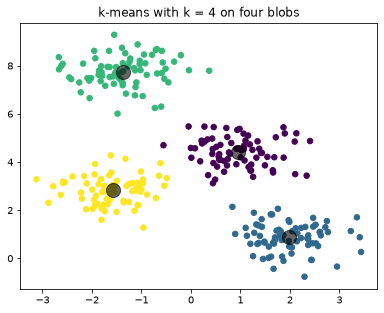

In [11]:
from sklearn.datasets import make_blobs

Xb, yb_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(Xb)
plt.scatter(Xb[:, 0], Xb[:, 1], c=kmeans.labels_, s=30, cmap="viridis")
plt.scatter(*kmeans.cluster_centers_.T, c="black", s=200, alpha=0.6)
plt.title("k-means with k = 4 on four blobs")
plt.show()

Next we write the EM loop ourselves for many columns. `pairwise_distances_argmin(X, centers)` returns, for each row, the index of the nearest centre (the E step); the M step averages the rows of each cluster with `.mean(0)`. The start is `n_clusters` rows drawn at random, controlled by `rseed`.

In [12]:
from sklearn.metrics import pairwise_distances_argmin


def find_clusters(X, n_clusters, rseed=2):
    rng = np.random.RandomState(rseed)
    centers = X[rng.permutation(X.shape[0])[:n_clusters]]           # random rows as the start
    while True:
        labels = pairwise_distances_argmin(X, centers)              # E step: assign
        new_centers = np.array([X[labels == i].mean(0) for i in range(n_clusters)])  # M step
        if np.all(centers == new_centers):
            return centers, labels
        centers = new_centers

**Predict.** The same function with two different random starts: will both find the four blobs?

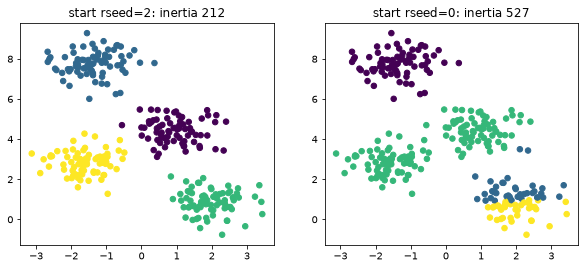

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, seed in zip(axes, [2, 0]):
    centers, labels = find_clusters(Xb, 4, rseed=seed)
    inertia = ((Xb - centers[labels]) ** 2).sum()
    ax.scatter(Xb[:, 0], Xb[:, 1], c=labels, s=30, cmap="viridis")
    ax.set_title(f"start rseed={seed}: inertia {inertia:.0f}")
plt.show()

**What do you see?** Compare the two inertias in the panel titles, and look for a blob that is split or two blobs that share a colour.

With one start the loop finds the four blobs; with the other it gets stuck in a worse local solution (two blobs share a centre, one blob is split) and a higher inertia. This is exactly why scikit-learn runs several starts (`n_init`) and keeps the lowest inertia.

Two more limits, shown with the same code base:

- **k must be chosen in advance.** Ask for six clusters on these four blobs and k-means obediently returns six, splitting real groups.
- **Boundaries are straight lines.** Every point goes to its nearest centre, so the border between two clusters is the straight line halfway between their centres. Curved groups such as two interleaved half-moons cannot be separated.

The next cell shows both. `make_moons` creates the half-moons. `SpectralClustering(affinity="nearest_neighbors")` first builds a graph that links each point to its nearest neighbours and then clusters that graph, so it follows the shape of the moons.

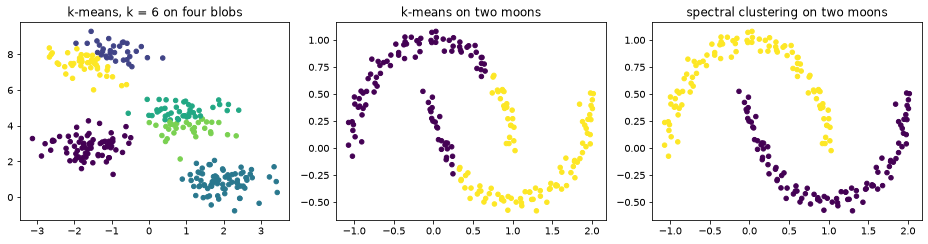

In [14]:
from sklearn.cluster import SpectralClustering
from sklearn.datasets import make_moons

Xm, _ = make_moons(200, noise=0.05, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].scatter(Xb[:, 0], Xb[:, 1], c=KMeans(6, n_init=10, random_state=0).fit_predict(Xb), s=20, cmap="viridis")
axes[0].set_title("k-means, k = 6 on four blobs")
axes[1].scatter(Xm[:, 0], Xm[:, 1], c=KMeans(2, n_init=10, random_state=0).fit_predict(Xm), s=20, cmap="viridis")
axes[1].set_title("k-means on two moons")
spectral = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=15,
                              assign_labels="kmeans", random_state=0)
axes[2].scatter(Xm[:, 0], Xm[:, 1], c=spectral.fit_predict(Xm), s=20, cmap="viridis")
axes[2].set_title("spectral clustering on two moons")
plt.tight_layout()

Finally, k-means can be slow on very large data because every iteration touches every row. `MiniBatchKMeans` updates the centres from small random batches instead; its result is slightly worse but much faster (used for the colour compression below).

> 📖 **Read more:** [extras/02-pdsh-kmeans.ipynb](extras/02-pdsh-kmeans.ipynb) (Python Data Science Handbook): the original chapter with its own explanations.

### Where k-means fails, and what to do

*Adapted from [Demonstration of k-means assumptions](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html) (scikit-learn developers, BSD-3-Clause).*

The scikit-learn example builds four data sets in which k-means produces unintuitive clusters:

- **Non-optimal number of clusters**: in a real setting there is no uniquely defined true number of clusters; it has to be chosen from data-based criteria and knowledge of the goal.
- **Anisotropically distributed blobs** (stretched ellipses): k-means minimises Euclidean distances to the centre, so it is most appropriate for round (isotropic) clusters.
- **Unequal variance**: k-means is equivalent to the maximum-likelihood estimate of a mixture of k Gaussian distributions with the *same* variance but different means.
- **Unevenly sized blobs**: there is no theoretical result that k-means needs similar sizes, but a single run can land in a poor local minimum, so several starts are needed.

The next cell creates the four data sets. A linear `transformation` stretches round blobs into ellipses; `cluster_std=[1.0, 2.5, 0.5]` gives three spreads; slicing keeps 500, 100 and 10 points of the three blobs.

In [15]:
n_samples, random_state = 1500, 170
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
Xa, ya = make_blobs(n_samples=n_samples, random_state=random_state)
X_aniso = np.dot(Xa, transformation)                                   # anisotropic blobs
X_varied, y_varied = make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state)
X_filtered = np.vstack((Xa[ya == 0][:500], Xa[ya == 1][:100], Xa[ya == 2][:10]))   # uneven sizes

Now k-means on each: two clusters for the plain blobs (a wrong k), three for the others with a single start (`n_init=1`) to make the last failure visible.

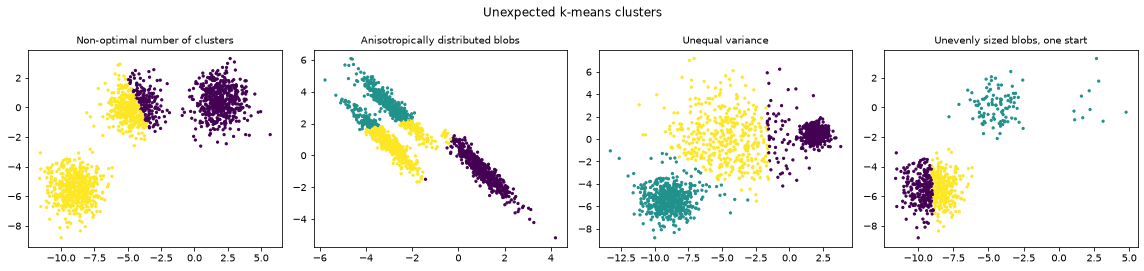

In [16]:
cases = [(Xa, 2, "Non-optimal number of clusters"), (X_aniso, 3, "Anisotropically distributed blobs"),
         (X_varied, 3, "Unequal variance"), (X_filtered, 3, "Unevenly sized blobs, one start")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (data, k, title) in zip(axes, cases):
    pred = KMeans(n_clusters=k, n_init=1, random_state=random_state).fit_predict(data)
    ax.scatter(data[:, 0], data[:, 1], c=pred, s=5)
    ax.set_title(title, fontsize=10)
plt.suptitle("Unexpected k-means clusters")
plt.tight_layout()

Possible solutions, again following the scikit-learn example:

- the wrong k is fixed by choosing k with care (next section);
- uneven sizes are often fixed by more random starts (`n_init=10`);
- for elongated clusters and unequal spreads, a **Gaussian mixture model** (`GaussianMixture`) also assumes Gaussian clusters but lets every cluster have its own shape and spread. It still needs the number of clusters.

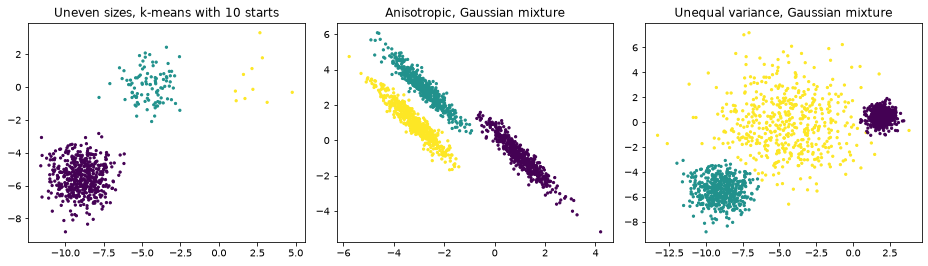

In [17]:
from sklearn.mixture import GaussianMixture

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(*X_filtered.T, s=5, c=KMeans(3, n_init=10, random_state=random_state).fit_predict(X_filtered))
axes[0].set_title("Uneven sizes, k-means with 10 starts")
for ax, data, title in [(axes[1], X_aniso, "Anisotropic, Gaussian mixture"), (axes[2], X_varied, "Unequal variance, Gaussian mixture")]:
    ax.scatter(*data.T, s=5, c=GaussianMixture(n_components=3, random_state=0).fit_predict(data))
    ax.set_title(title)
plt.tight_layout()

In high-dimensional spaces Euclidean distances become inflated and similar to each other; reducing the dimension first (block 2) helps and speeds up the computation. When clusters are round, of similar spread and not too sparse, k-means is effective and one of the fastest clustering algorithms.

> 📖 **Read more:** [extras/03-kmeans-assumptions.ipynb](extras/03-kmeans-assumptions.ipynb) (scikit-learn gallery): the original example with larger figures.

### Two classic uses: digits and colour compression

*Code adapted from [In Depth: k-Means Clustering](https://jakevdp.github.io/PythonDataScienceHandbook/05.11-k-means.html), Python Data Science Handbook (Jake VanderPlas, code MIT); explanations ours.*

Two classic applications show what k-means does beyond customer segments: it finds typical images without labels, and it compresses an image to a small palette of colours.

#### Handwritten digits

scikit-learn ships 1,797 images of handwritten digits, each 8 × 8 = 64 grey values. We cluster them into ten groups *without* the labels and then look at the ten centres: each centre is itself an 8 × 8 image, the "average" image of its cluster.

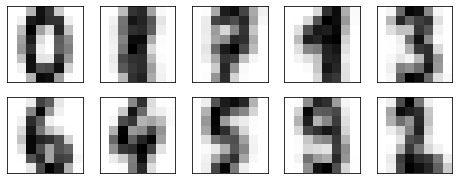

In [18]:
from sklearn.datasets import load_digits

digits = load_digits()
km_digits = KMeans(n_clusters=10, n_init=10, random_state=0)
clusters = km_digits.fit_predict(digits.data)
fig, axes = plt.subplots(2, 5, figsize=(8, 3))
for ax, center in zip(axes.flat, km_digits.cluster_centers_.reshape(10, 8, 8)):
    ax.set(xticks=[], yticks=[])
    ax.imshow(center, interpolation="nearest", cmap=plt.cm.binary)
plt.show()

Most centres are recognisable digits, although the algorithm never saw a label. How well do the clusters match the true digits? Cluster numbers are arbitrary, so we give each cluster the most common true label among its members (`scipy.stats.mode`) and then compute the accuracy and a confusion matrix.

In [19]:
from scipy.stats import mode
from sklearn.metrics import accuracy_score, confusion_matrix

mapped = np.zeros_like(clusters)
for i in range(10):
    mask = clusters == i
    mapped[mask] = mode(digits.target[mask], keepdims=False).mode
print("accuracy after mapping clusters to digits:", round(accuracy_score(digits.target, mapped), 3))
pd.DataFrame(confusion_matrix(digits.target, mapped), index=digits.target_names, columns=digits.target_names)

accuracy after mapping clusters to digits: 0.792


,0,1,2,3,4,5,6,7,8,9
0,176,0,0,0,2,0,0,0,0,0
1,0,154,24,1,0,1,2,0,0,0
2,1,10,148,13,0,0,0,3,0,2
3,0,7,0,154,0,2,0,7,0,13
4,0,5,0,0,165,0,0,11,0,0
5,0,0,0,2,2,136,1,0,0,41
6,1,3,0,0,0,0,177,0,0,0
7,0,4,0,0,0,1,0,174,0,0
8,0,106,3,2,0,4,2,5,0,52
9,0,21,0,6,0,6,0,8,0,139


About four in five images land in the cluster of their own digit. The confusion matrix (rows: true digit, columns: cluster label) shows where it fails: no cluster ends up labelled 8, because most eights are mixed with ones and nines, and many fives fall into the nines' cluster. This is a common way to *evaluate* clustering when labels exist for a test: a good match means the structure k-means found is the structure people care about. With a t-SNE map of the digits as input (block 2), the match becomes much better.

#### Colour compression

A colour image is a table with one row per pixel and three columns (red, green, blue). k-means with 16 clusters finds 16 representative colours; replacing every pixel by its cluster centre gives an image with only 16 colours. We use `MiniBatchKMeans` because the photo has over 270,000 pixels.

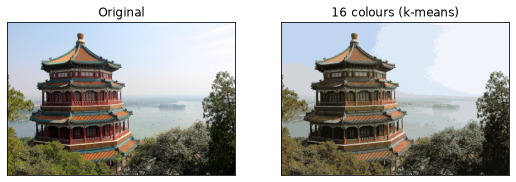

In [20]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.datasets import load_sample_image

china = load_sample_image("china.jpg")                    # 427 x 640 pixels, 3 colour channels
pixels = (china / 255.0).reshape(-1, 3)
mbk = MiniBatchKMeans(n_clusters=16, n_init=3, random_state=0).fit(pixels)
recoloured = mbk.cluster_centers_[mbk.predict(pixels)].reshape(china.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), subplot_kw=dict(xticks=[], yticks=[]))
axes[0].imshow(china)
axes[0].set_title("Original")
axes[1].imshow(recoloured)
axes[1].set_title("16 colours (k-means)")
plt.show()

Some detail is lost, but the image needs a palette of 16 colours plus one small number per pixel instead of three full colour values. The same idea, **vector quantisation**, was used for speech coding (the Linde–Buzo–Gray algorithm, 1980).

## Choosing the number of clusters: elbow and silhouette

k-means needs k before it runs. Two common aids help to choose it: the elbow method and the silhouette.

### The elbow method

The **elbow method** fits k = 2, 3, 4, … and plots the inertia against k. The inertia always falls (with one cluster per row it is 0), so look for the **elbow**: the k after which an extra cluster gains little. "Elbow" is the usual name for this rule of thumb, not a formal test.

### The silhouette

The **silhouette** (Rousseeuw, 1987) measures how well one row fits its own cluster compared with the nearest other cluster. Let a be the row's mean distance to the other rows of its own cluster and b its mean distance to the rows of the nearest other cluster. Its silhouette is (b − a) / max(a, b): near 1, the row sits well inside its cluster; near 0, it lies between two clusters; below 0, it is probably in the wrong one. The **mean silhouette** over all rows summarises a clustering, and the k with the highest mean is a candidate.

By hand for the value 1 in the k-means hand example (clusters {1, 2, 3} and {8, 9, 15}): a = (1 + 2) / 2 = 1.5, b = (7 + 8 + 14) / 3 ≈ 9.67, so the silhouette is (9.67 − 1.5) / 9.67 ≈ 0.84.

On clean toy data both aids point to the same k:

![Two line charts for data with four true groups: the inertia drops steeply until k = 4 and then flattens, and the mean silhouette peaks at 0.81 for k = 4](../figures/elbow_silhouette.png)

### Elbow and silhouette on the Telco customers

Next both aids on the standardised Telco customers. The loop fits k-means for k = 2 to 8 and stores the inertia (`inertia_`) and the mean silhouette (`silhouette_score(Z, labels)`).

**Predict.** Will the inertia curve of the Telco customers show a clear elbow, and which k between 2 and 8 will have the highest mean silhouette?

k,2,3,4,5,6,7,8
inertia,9700.83,6176.705,4144.588,3108.131,2559.790,2177.298,1882.505
silhouette,0.48,0.452,0.472,0.444,0.438,0.433,0.431


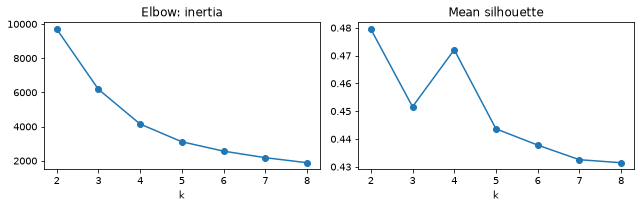

In [21]:
rows = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z_telco)
    rows.append({"k": k, "inertia": km_k.inertia_, "silhouette": silhouette_score(Z_telco, km_k.labels_)})
choice = pd.DataFrame(rows).set_index("k")
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
choice["inertia"].plot(ax=axes[0], marker="o", title="Elbow: inertia")
choice["silhouette"].plot(ax=axes[1], marker="o", title="Mean silhouette")
plt.tight_layout()
choice.round(3).T

**What do you see?** Look for a sharp bend in the left curve and for the highest point of the right one.

On real data the picture is less clear: no sharp elbow, and the silhouette varies little between k = 2 and k = 4. Both aids give evidence, not an answer; k is also chosen by **purpose** (how many segments can a marketing team serve?) and checked for stability later.

We take three segments and describe them with their means and with two columns the clustering did **not** see: the churn rate and the share of monthly contracts. `groupby(...).agg(name=(column, function))` builds such a **profile** table.

In [22]:
telco["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z_telco)
telco.groupby("segment").agg(
    customers=("tenure", "size"),
    tenure=("tenure", "mean"),
    monthly=("MonthlyCharges", "mean"),
    churn_rate=("Churn", lambda s: (s == "Yes").mean()),
    month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
).round(2)

,customers,tenure,monthly,churn_rate,month_to_month
segment,,,,,
0,2200,58.56,89.70,0.15,0.26
1,2147,29.59,26.58,0.12,0.44
2,2685,13.27,74.96,0.47,0.87


One reading: long-standing customers with high bills, low-cost customers, and new customers with high bills who are mostly on monthly contracts and churn far more often than the others. Names like these are interpretations that the business must confirm. Because churn was kept out of the clustering, the difference in churn rates is genuine evidence that the segments mean something.

> **Note.** `silhouette_score` computes all pairwise distances, which grows with the square of the number of rows. On more than about 20,000 rows pass `sample_size=10_000, random_state=0`. Other criteria exist: the **gap statistic** (Tibshirani, Walther and Hastie, 2001) compares the inertia with that of uniform random data, and for Gaussian mixtures information criteria (BIC) choose the number of components.

### Silhouette plots

*Adapted from [Selecting the number of clusters with silhouette analysis on KMeans clustering](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html) (scikit-learn developers, BSD-3-Clause).*

The mean silhouette hides a lot. A **silhouette plot** shows the silhouette of every row as a horizontal bar, sorted within each cluster, with the clusters stacked. It reveals three things at once: clusters with many rows below the mean (badly separated), clusters with negative values (rows that probably belong elsewhere), and the cluster sizes (the thickness of each band). In the scikit-learn example, a k is judged a bad pick when some clusters stay below the average silhouette or when the band widths fluctuate strongly.

`silhouette_samples(X, labels)` returns one silhouette per row; `fill_betweenx` draws each cluster's sorted values as a band. We use a random sample of 2,000 Telco customers to keep the plot fast and readable.

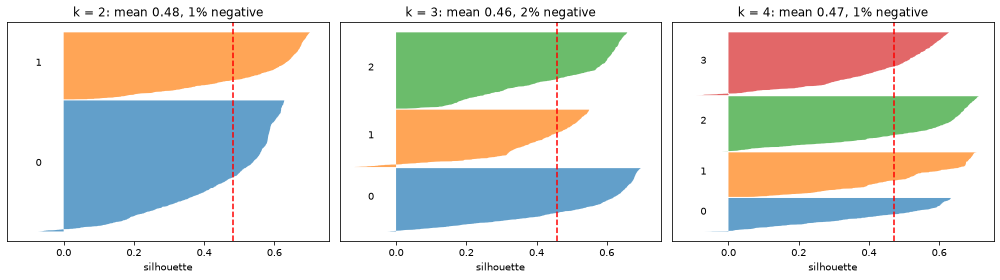

In [23]:
from sklearn.metrics import silhouette_samples

sample = np.random.default_rng(0).choice(len(Z_telco), size=2000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z_telco)[sample]
    sil = silhouette_samples(Z_telco[sample], lab)
    y_lower = 10
    for i in range(k):
        vals = np.sort(sil[lab == i])
        ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, alpha=0.7)
        ax.text(-0.08, y_lower + len(vals) / 2, str(i))
        y_lower += len(vals) + 10
    ax.axvline(sil.mean(), color="red", linestyle="--")
    ax.set(title=f"k = {k}: mean {sil.mean():.2f}, {(sil < 0).mean():.0%} negative", xlabel="silhouette", yticks=[])
plt.tight_layout()

Read the bands, not only the red mean line: which k leaves no cluster mostly below the mean, and how large is the share of negative values in the titles? Rows with negative values sit closer to another segment than to their own: the segments overlap, as the flat silhouette curve already suggested.

> 📖 **Read more:** [extras/04-kmeans-silhouette-analysis.ipynb](extras/04-kmeans-silhouette-analysis.ipynb) (scikit-learn gallery): silhouette plots for k = 2 to 6 on toy data with one distinct and three close clusters, next to the clustered points.

## From customers to listings

The rest of the block uses the Berlin listings of Inside Airbnb (snapshot of 26 June 2026). The practical question: **what kinds of Airbnb offers exist in Berlin?** A city office that enforces the short-term rental rules, or a new host, would like a handful of types rather than thousands of single listings.

Each listing with a price is described by six numbers: nightly price, number of guests, minimum nights, nights bookable in the next year, reviews in the last twelve months, and distance to Alexanderplatz. Price, minimum nights and reviews are strongly skewed, so they enter on the log scale (Session 4); then all six are standardised. Room type, district and host stay out and describe the clusters afterwards.

The next cell converts the coordinates into kilometres east and north of Alexanderplatz (one degree of latitude is about 111.2 km; a degree of longitude is shorter by the cosine of the latitude) and builds the six features. `np.log1p` is log(1 + x), which accepts zero reviews.

**Predict.** The snapshot has 10,221 listings. How many of them will have a price, and so stay in the clustering?

In [24]:
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
d = listings.dropna(subset=["price", "minimum_nights"]).reset_index(drop=True)
lat0, lon0 = 52.5219, 13.4132                                       # Alexanderplatz
d["north_km"] = (d["latitude"] - lat0) * 111.2
d["east_km"] = (d["longitude"] - lon0) * 111.2 * np.cos(np.radians(lat0))
d["km_centre"] = np.hypot(d["north_km"], d["east_km"])

features = pd.DataFrame({
    "log_price": np.log(d["price"]),
    "guests": d["accommodates"],
    "log_min_nights": np.log(d["minimum_nights"]),
    "availability_365": d["availability_365"],
    "log_reviews_ltm": np.log1p(d["number_of_reviews_ltm"]),
    "km_centre": d["km_centre"],
})
Z = StandardScaler().fit_transform(features)
print(len(listings), "listings,", len(d), "with a price; Z has shape", Z.shape)

10221 listings, 6753 with a price; Z has shape (6753, 6)


> **Note.** Inside Airbnb scrapes public listing pages. Describe clusters in aggregate (sizes, medians, shares) and never single out or name hosts.

## Hierarchical clustering and dendrograms

**Agglomerative hierarchical clustering** starts with every row as its own cluster and repeatedly merges the two closest clusters until one is left. The result is a tree, drawn as a **dendrogram**: the leaves are the rows, each merge is a horizontal bar, and its height is the distance at which the two clusters joined. A horizontal cut through the tree gives a flat clustering; the number of branches it crosses is the number of clusters. A family tree read upside down is a good picture. (The opposite direction, **divisive** clustering, starts with one cluster and splits it; it is rarely used.)

How far apart are two *clusters*? The **linkage** decides:

- **single**: the closest pair of rows, one from each cluster (can form long chains);
- **complete**: the farthest pair (compact clusters);
- **average**: the mean of all pairs;
- **Ward**: the merge that raises the within-cluster sum of squares least (close in spirit to k-means; the usual default).

![Left: 15 points in three coloured groups. Right: their Ward dendrogram; a dashed horizontal cut at height 4.7 crosses three branches, giving the same three groups](../figures/dendrogram.png)

The dendrogram shows structure at every level at once, so k need not be fixed in advance: long vertical branches (a large gap between merge heights) suggest a natural number of clusters. Hierarchies are also meaningful in themselves: biological taxonomies, product categories, and Berlin itself (12 districts, each split into neighbourhoods).

**Predict.** For the four values 1, 2, 5 and 11, at which heights do single and complete linkage make their three merges?

`scipy.cluster.hierarchy.linkage` returns one row per merge: the two merged clusters, the merge height (column 2) and the size of the new cluster.

In [25]:
tiny = np.array([[1.0], [2.0], [5.0], [11.0]])
print("single:  ", linkage(tiny, method="single")[:, 2])
print("complete:", linkage(tiny, method="complete")[:, 2])
print(linkage(tiny, method="complete"))

single:   [1. 3. 6.]
complete: [ 1.  4. 10.]
[[ 0.  1.  1.  2.]
 [ 2.  4.  4.  3.]
 [ 3.  5. 10.  4.]]


Both trees merge {1, 2} first, then add 5, then 11, but at different heights: single linkage measures from the nearest member (2 is 3 away from 5), complete linkage from the farthest (1 is 4 away from 5, and 1 is 10 away from 11).

### Comparing the linkages

*Adapted from [Comparing different hierarchical linkage methods on toy datasets](https://scikit-learn.org/stable/auto_examples/cluster/plot_linkage_comparison.html) (scikit-learn developers, BSD-3-Clause).*

The scikit-learn example runs the four linkages on six two-dimensional data sets. Its main observations:

- **single** linkage is fast and can perform well on non-globular data (rings, moons), but it performs poorly in the presence of noise: one point lying between two groups can chain them together;
- **average** and **complete** linkage perform well on cleanly separated globular clusters, but have mixed results otherwise;
- **Ward** is the most effective method for noisy data.

These intuitions come from two dimensions and may not carry over to high-dimensional data. The next cell builds the data sets (rings, moons, blobs of different spread, stretched blobs, round blobs and structureless noise) and standardises each.

In [26]:
from sklearn import datasets as skdata

n = 500
Xv, yv = make_blobs(n_samples=n, random_state=170)
toy_sets = [
    (skdata.make_circles(n_samples=n, factor=0.5, noise=0.05, random_state=170)[0], 2),
    (skdata.make_moons(n_samples=n, noise=0.05, random_state=170)[0], 2),
    (make_blobs(n_samples=n, cluster_std=[1.0, 2.5, 0.5], random_state=170)[0], 3),
    (np.dot(Xv, [[0.6, -0.6], [-0.4, 0.8]]), 3),
    (Xv, 3),
    (np.random.RandomState(170).rand(n, 2), 3),
]
toy_sets = [(StandardScaler().fit_transform(data), k) for data, k in toy_sets]

Now the grid: one row per data set, one column per linkage. `AgglomerativeClustering(n_clusters=k, linkage=...)` fits each combination.

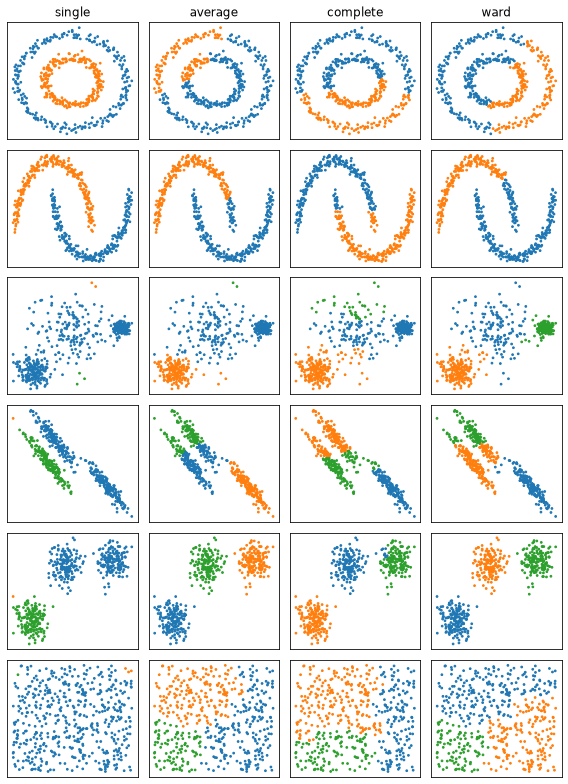

In [27]:
linkages = ["single", "average", "complete", "ward"]
fig, axes = plt.subplots(len(toy_sets), 4, figsize=(8, 11))
for r, (data, k) in enumerate(toy_sets):
    for c, method in enumerate(linkages):
        pred = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(data)
        axes[r, c].scatter(data[:, 0], data[:, 1], s=3, c=pred, cmap="tab10", vmax=9)
        axes[r, c].set(xticks=[], yticks=[])
        if r == 0:
            axes[r, c].set_title(method)
plt.tight_layout()

Single linkage separates the rings and moons perfectly but on the blobs it puts almost every point into one or two clusters and leaves tiny leftovers; Ward cuts the rings and moons in the wrong places but handles the blobs. No linkage is best everywhere, and every linkage returns clusters for the structureless square in the last row.

### Ward on the Berlin listings

Hierarchical clustering needs all pairwise distances, so memory grows with the square of the number of rows; we use a random sample of 2,000. `dendrogram(..., truncate_mode="lastp", p=25)` draws only the top 25 merges, and `fcluster(tree, t=5, criterion="maxclust")` cuts the tree into five clusters.

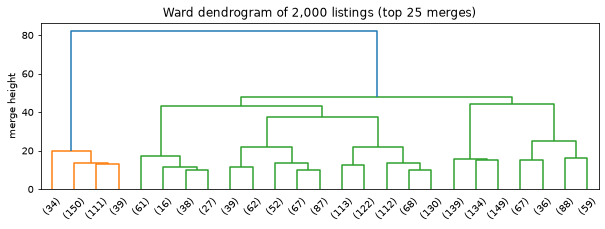

last five merge heights: [37.4 43.1 44.3 47.6 82.3]
cluster sizes: {1: 334, 2: 142, 3: 852, 4: 422, 5: 250}


In [28]:
rng = np.random.default_rng(0)
idx = rng.choice(len(Z), size=2000, replace=False)
Zs = Z[idx]
tree = linkage(Zs, method="ward")

fig, ax = plt.subplots(figsize=(10, 3))
dendrogram(tree, truncate_mode="lastp", p=25, ax=ax)
ax.set(title="Ward dendrogram of 2,000 listings (top 25 merges)", ylabel="merge height")
plt.show()

ward5 = fcluster(tree, t=5, criterion="maxclust")
print("last five merge heights:", tree[-5:, 2].round(1))
print("cluster sizes:", pd.Series(ward5).value_counts().sort_index().to_dict())

**What do you see?** Look for the merge whose vertical branch is much longer than all the others.

The last merge is far higher than the ones below it: at the top, the listings split into two groups that are far apart. Below that the heights grow slowly, so there is no single natural number of clusters between three and six; we cut at five to compare with k-means later.

scikit-learn's `AgglomerativeClustering` gives the same partition. The **adjusted Rand index** (ARI) compares two partitions of the same rows: 1 means identical (whatever the label numbers), about 0 means chance agreement.

In [29]:
agg = AgglomerativeClustering(n_clusters=5, linkage="ward").fit(Zs)
print("ARI scipy vs scikit-learn:", adjusted_rand_score(ward5, agg.labels_))

ARI scipy vs scikit-learn: 1.0


### A dendrogram from scikit-learn

*Adapted from [Plot Hierarchical Clustering Dendrogram](https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html) (scikit-learn developers, BSD-3-Clause).*

`AgglomerativeClustering` does not draw dendrograms itself. With `distance_threshold=0, n_clusters=None` it computes the full tree and stores the merges in `children_` and their heights in `distances_`. The helper below counts the rows under each merge and builds the linkage matrix that scipy's `dendrogram` expects. `truncate_mode="level", p=3` shows only the top three levels; numbers in brackets are cluster sizes.

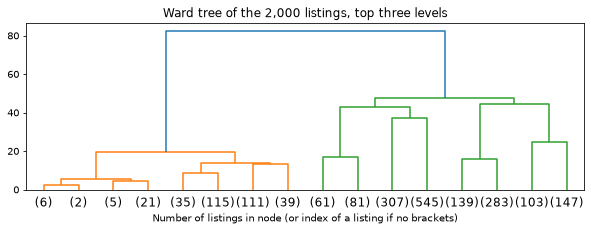

In [30]:
def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        counts[i] = sum(1 if child < n_samples else counts[child - n_samples] for child in merge)
    linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix, **kwargs)


full_tree = AgglomerativeClustering(distance_threshold=0, n_clusters=None).fit(Zs)
plt.figure(figsize=(10, 3))
plot_dendrogram(full_tree, truncate_mode="level", p=3)
plt.title("Ward tree of the 2,000 listings, top three levels")
plt.xlabel("Number of listings in node (or index of a listing if no brackets)")
plt.show()

Alternatively, `AgglomerativeClustering(distance_threshold=h, n_clusters=None)` cuts the tree at height h instead of at a fixed number of clusters.

> 📖 **Read more:** [extras/05-agglomerative-dendrogram.ipynb](extras/05-agglomerative-dendrogram.ipynb) and [extras/06-linkage-comparison.ipynb](extras/06-linkage-comparison.ipynb) (scikit-learn gallery): the original examples, including the run time of each linkage. The ISLP lab [extras/23-islp-unsupervised-lab.ipynb](extras/23-islp-unsupervised-lab.ipynb) adds correlation-based distances and cuts the dendrogram of cancer cell lines.

## Density-based clustering (DBSCAN)

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise; Ester et al., 1996) defines clusters as **dense regions**. Picture people at a festival: groups are where people stand close together, and the few wanderers in between belong to no group. Two settings: a radius **eps** and a count **min_samples**.

- A **core point** has at least min_samples rows (itself included) within eps.
- A **border point** is within eps of a core point but is not core itself.
- A **noise point** is neither and gets the label −1.

Clusters grow by linking core points that lie within eps of each other, plus their border points. The number of clusters is a result, not an input, and DBSCAN finds clusters of any shape.

```mermaid
flowchart LR
    P["A row"] --> C{"At least min_samples<br/>rows within eps?"}
    C -->|yes| CORE["core point"]
    C -->|no| N{"Within eps of<br/>a core point?"}
    N -->|yes| BORDER["border point"]
    N -->|no| NOISE["noise: label -1"]
```

**Predict.** The values 1, 2, 3, 7, 12, 13, 14 with eps = 1.5 and min_samples = 3: which are core, border and noise points?

In [31]:
values = np.array([1, 2, 3, 7, 12, 13, 14], dtype=float).reshape(-1, 1)
db = DBSCAN(eps=1.5, min_samples=3).fit(values)
print("labels:      ", db.labels_)
print("core indices:", db.core_sample_indices_)

labels:       [ 0  0  0 -1  1  1  1]
core indices: [1 5]


2 and 13 (indices 1 and 5) are core points, their neighbours are border points, and 7 is noise.

### Core, border and noise points, and metrics with known labels

*Adapted from [Demo of DBSCAN clustering algorithm](https://scikit-learn.org/stable/auto_examples/cluster/plot_dbscan.html) (scikit-learn developers, BSD-3-Clause).*

DBSCAN finds core samples in regions of high density and expands clusters from them; it is good for data that contain clusters of similar density. The example generates three blobs with known labels, standardises them and runs DBSCAN with eps = 0.3 and min_samples = 10.

In [32]:
from sklearn import metrics

Xd, labels_true = make_blobs(n_samples=750, centers=[[1, 1], [-1, -1], [1, -1]], cluster_std=0.4, random_state=0)
Xd = StandardScaler().fit_transform(Xd)
db = DBSCAN(eps=0.3, min_samples=10).fit(Xd)
labels_d = db.labels_
n_clusters_ = len(set(labels_d)) - (1 if -1 in labels_d else 0)
print("Estimated number of clusters:", n_clusters_, "| noise points:", list(labels_d).count(-1))

Estimated number of clusters: 3 | noise points: 18


Because the blobs come with true labels, we can use **external** metrics, which compare the clusters with a known grouping:

- **homogeneity**: each cluster contains only members of one true class;
- **completeness**: all members of a true class end up in the same cluster;
- **V-measure**: the harmonic mean of the two;
- **adjusted Rand index** and **adjusted mutual information**: agreement between the two partitions, corrected so that random labels score about 0.

Without true labels, only internal measures such as the silhouette remain.

In [33]:
print(f"Homogeneity:  {metrics.homogeneity_score(labels_true, labels_d):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels_d):.3f}")
print(f"V-measure:    {metrics.v_measure_score(labels_true, labels_d):.3f}")
print(f"ARI:          {metrics.adjusted_rand_score(labels_true, labels_d):.3f}")
print(f"AMI:          {metrics.adjusted_mutual_info_score(labels_true, labels_d):.3f}")
print(f"Silhouette:   {metrics.silhouette_score(Xd, labels_d):.3f}")

Homogeneity:  0.953
Completeness: 0.883
V-measure:    0.917
ARI:          0.952
AMI:          0.916
Silhouette:   0.626


The plot marks core samples with large dots and border samples with small dots, coloured by cluster; noise is black. `db.core_sample_indices_` tells which rows are core.

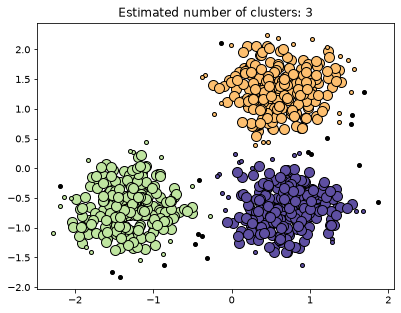

In [34]:
core_mask = np.zeros_like(labels_d, dtype=bool)
core_mask[db.core_sample_indices_] = True
colours = [plt.cm.Spectral(v) for v in np.linspace(0, 1, len(set(labels_d)))]
for k, col in zip(sorted(set(labels_d)), colours):
    col = [0, 0, 0, 1] if k == -1 else col
    member = labels_d == k
    plt.plot(*Xd[member & core_mask].T, "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=10)
    plt.plot(*Xd[member & ~core_mask].T, "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=4)
plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

### Hot spots on the Berlin map

DBSCAN was built for spatial databases, so its natural use here is the **map**: where are the hot spots of listings? The coordinates are already in kilometres, so no scaling is needed. To choose eps we look at the distance of each listing to its 30th neighbour (`NearestNeighbors(...).kneighbors`): with min_samples = 30, a listing is a core point when that distance is at most eps. Plotting these distances sorted (a **k-distance plot**) and looking for the bend is the standard way to choose eps.

km to the 30th neighbour, 10/50/90 % quantiles: [0.2  0.38 1.82]


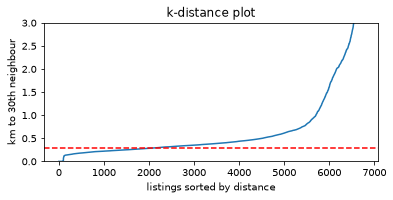

In [35]:
C = d[["east_km", "north_km"]].to_numpy()
dist, _ = NearestNeighbors(n_neighbors=30).fit(C).kneighbors(C)
k_dist = np.sort(dist[:, -1])
print("km to the 30th neighbour, 10/50/90 % quantiles:", np.quantile(k_dist, [0.1, 0.5, 0.9]).round(2))
plt.figure(figsize=(6, 2.5))
plt.plot(k_dist)
plt.axhline(0.3, color="red", linestyle="--")
plt.gca().set(ylim=(0, 3), xlabel="listings sorted by distance", ylabel="km to 30th neighbour", title="k-distance plot")
plt.show()

The median distance to the 30th neighbour is about 380 m, and the sorted curve bends upwards beyond that. With eps = 0.3 km (the red line) the densest third of the listings become core points, which separates dense areas from the rest. Next we run DBSCAN and draw the map: noise in grey, every hot spot in its own colour. `s.mode()[0]` gives the most common neighbourhood of a hot spot.

23 hot spots; 3407 listings outside any hot spot


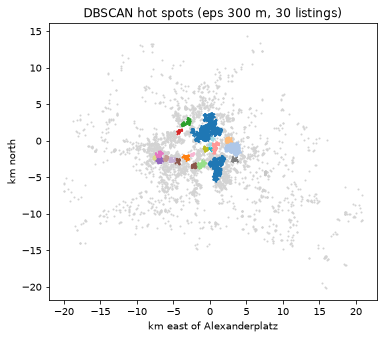

,listings,area,median_price
hot_spot,,,
0,1300,Brunnenstr. Süd,171.165
1,477,südliche Luisenstadt,136.000
2,401,Frankfurter Allee Süd FK,138.000
5,141,Brunnenstr. Nord,177.000


In [36]:
d["hot_spot"] = DBSCAN(eps=0.3, min_samples=30).fit_predict(C)
outside = d["hot_spot"] == -1
print(d["hot_spot"].max() + 1, "hot spots;", outside.sum(), "listings outside any hot spot")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(d.loc[outside, "east_km"], d.loc[outside, "north_km"], s=1, color="lightgrey")
ax.scatter(d.loc[~outside, "east_km"], d.loc[~outside, "north_km"], s=1, c=d.loc[~outside, "hot_spot"], cmap="tab20")
ax.set(xlabel="km east of Alexanderplatz", ylabel="km north", aspect="equal", title="DBSCAN hot spots (eps 300 m, 30 listings)")
plt.show()
(d[~outside].groupby("hot_spot")
 .agg(listings=("id", "size"), area=("neighbourhood", lambda s: s.mode()[0]), median_price=("price", "median"))
 .nlargest(4, "listings"))

**What do you see?** Find where the coloured hot spots sit relative to Alexanderplatz at (0, 0), and where the grey listings outside any hot spot are.

The largest hot spot covers central Mitte (its most common neighbourhood is Brunnenstraße Süd, north-west of Alexanderplatz), followed by parts of Kreuzberg (südliche Luisenstadt) and Friedrichshain. A city office could use such hot spots to decide where to check registration numbers first.

### DBSCAN on the six listing features

DBSCAN on the six **features** tells a different story. The next cell tries two radii on `Z`. `labels.nunique() - (labels == -1).any()` counts the clusters without the noise label.

In [37]:
for eps in (0.5, 1.0):
    labels = pd.Series(DBSCAN(eps=eps, min_samples=10).fit_predict(Z))
    print(f"eps {eps}: {labels.nunique() - (labels == -1).any()} clusters, {(labels == -1).sum()} noise points")

eps 0.5: 16 clusters, 3644 noise points


eps 1.0: 2 clusters, 224 noise points


A small eps declares more than half the listings noise (3,644 of 6,753); a larger one finds only two clusters and leaves 224 noise points. The listings form **one continuous cloud** with denser and sparser parts, not separate blobs. That is a finding, not a failure: any segmentation of these listings cuts a continuum. The noise points at eps = 1.0 are the unusual listings that block 2 examines as anomalies.

> **Note.** eps depends on the units and on the number of columns. Scale first and choose eps from the neighbour distances, not by guessing. In many dimensions distances become similar to each other and density is hard to estimate; reduce to a few principal components first (block 2).

### HDBSCAN: DBSCAN over all values of eps

*Adapted from [Demo of HDBSCAN clustering algorithm](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html) (scikit-learn developers, BSD-3-Clause).*

DBSCAN's eps hardly has a proper default and must be tuned for each data set; one global eps also fails when clusters differ in density. **HDBSCAN** (in scikit-learn since version 1.3) can be seen as clustering over all possible values of eps and extracting the best clusters from all of them. Two consequences:

- it is **scale-invariant**: multiplying the data by 3 changes nothing, while DBSCAN would need eps multiplied by 3 too;
- it does **multi-scale clustering**: it can find dense and sparse clusters in the same data.

The data set below has two dense, close clusters and two sparse, distant ones. The code passes `HDBSCAN(copy=True)` explicitly: scikit-learn is changing the default of `copy`, and setting it avoids a warning.

In [38]:
from sklearn.cluster import HDBSCAN

Xh, yh_true = make_blobs(n_samples=750, centers=[[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]],
                         cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0)


def show(ax, labels, title):
    ax.scatter(*Xh[labels >= 0].T, c=labels[labels >= 0], s=6, cmap="tab10")
    ax.scatter(*Xh[labels < 0].T, c="black", marker="x", s=6)
    ax.set_title(f"{title}: {labels.max() + 1} clusters", fontsize=10)

**Predict.** Can any single eps separate the two dense clusters *and* keep each sparse cluster in one piece? The cell compares DBSCAN with eps 0.7 and 0.3 with HDBSCAN at its defaults.

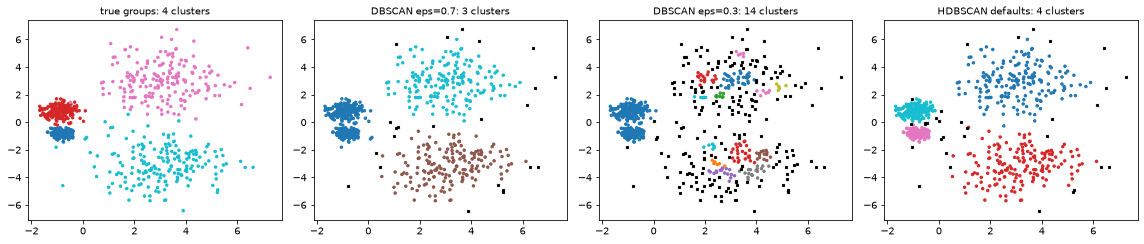

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
show(axes[0], yh_true, "true groups")
show(axes[1], DBSCAN(eps=0.7).fit_predict(Xh), "DBSCAN eps=0.7")
show(axes[2], DBSCAN(eps=0.3).fit_predict(Xh), "DBSCAN eps=0.3")
show(axes[3], HDBSCAN(copy=True).fit_predict(Xh), "HDBSCAN defaults")
plt.tight_layout()

A large eps merges the two dense clusters; a small eps fragments the sparse ones and marks much of them as noise. HDBSCAN adapts to the multi-scale structure without tuning.

HDBSCAN still has two settings with a clear meaning:

- **`min_cluster_size`**: the smallest group that counts as a cluster; smaller groups become noise. Too small values pick up false sub-clusters; larger values are more robust to noise. Default 5.
- **`min_samples`**: the number of neighbours for a point to count as a core point (defaults to `min_cluster_size`). Larger values make the result more conservative: more noise, small clusters may be lost. Tune it after `min_cluster_size`.

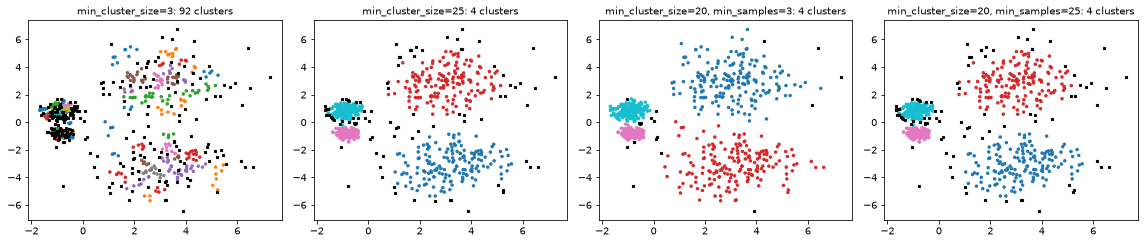

In [40]:
settings = [{"min_cluster_size": 3}, {"min_cluster_size": 25}, {"min_cluster_size": 20, "min_samples": 3},
            {"min_cluster_size": 20, "min_samples": 25}]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, params in zip(axes, settings):
    show(ax, HDBSCAN(copy=True, **params).fit_predict(Xh), ", ".join(f"{k}={v}" for k, v in params.items()))
plt.tight_layout()

During `fit`, HDBSCAN builds a single-linkage tree that encodes the DBSCAN clustering for every eps. `dbscan_clustering(cut_distance=...)` extracts one of them without refitting, so you can still get a DBSCAN result for any eps from the same model.

> 📖 **Read more:** [extras/07-dbscan.ipynb](extras/07-dbscan.ipynb) and [extras/08-hdbscan.ipynb](extras/08-hdbscan.ipynb) (scikit-learn gallery): the original examples, including the scale-invariance demonstration and `dbscan_clustering`.

### All methods on the same toy data

*Adapted from [Comparing different clustering algorithms on toy datasets](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html) (scikit-learn developers, BSD-3-Clause).*

The scikit-learn example tunes each algorithm for each data set; the last data set has no structure at all and is a "null" case where every algorithm should ideally refuse to cluster. Below is a reduced version with the five methods of this block and the data sets of the linkage comparison. The parameters are those of the example after standardising.

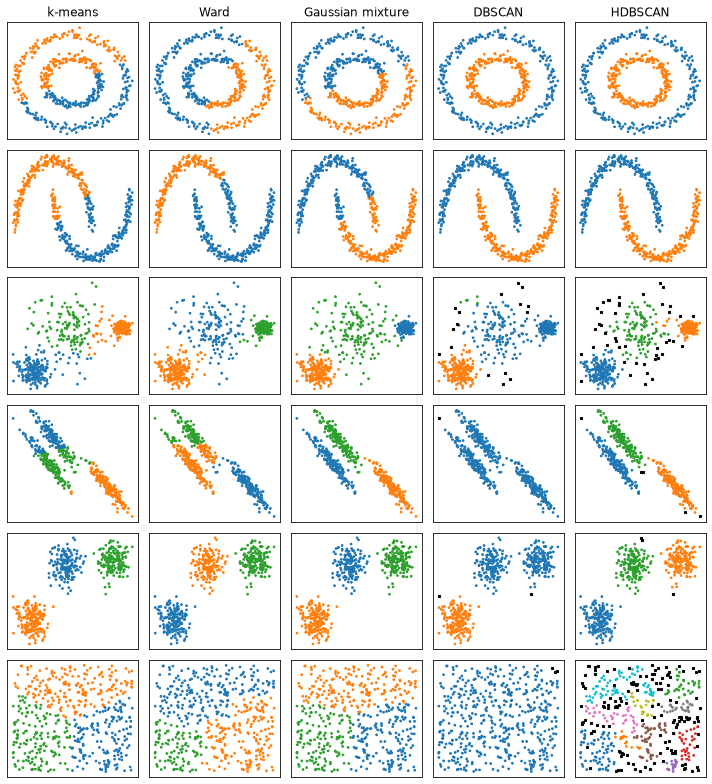

In [41]:
def methods(k):
    return {"k-means": KMeans(n_clusters=k, n_init=10, random_state=0),
            "Ward": AgglomerativeClustering(n_clusters=k, linkage="ward"),
            "Gaussian mixture": GaussianMixture(n_components=k, covariance_type="full", random_state=0),
            "DBSCAN": DBSCAN(eps=0.3),
            "HDBSCAN": HDBSCAN(min_samples=3, min_cluster_size=15, copy=True)}


fig, axes = plt.subplots(len(toy_sets), 5, figsize=(10, 11))
for r, (data, k) in enumerate(toy_sets):
    for c, (name, model) in enumerate(methods(k).items()):
        pred = model.fit_predict(data)
        axes[r, c].scatter(*data[pred >= 0].T, s=3, c=pred[pred >= 0], cmap="tab10", vmin=0, vmax=9)
        axes[r, c].scatter(*data[pred < 0].T, s=6, c="black", marker="x")
        axes[r, c].set(xticks=[], yticks=[], title=name if r == 0 else "")
plt.tight_layout()

Black crosses are noise points. The density methods follow rings and moons; the centroid and mixture methods do better on blobs. On the structureless square in the last row, DBSCAN returns a single cluster, while HDBSCAN with these settings reports a dozen small ones: a reminder that every method can find groups in noise. Which method fits depends on what "a group" means in your data.

> 📖 **Read more:** [extras/09-clustering-algorithms-compared.ipynb](extras/09-clustering-algorithms-compared.ipynb) (scikit-learn gallery): eleven algorithms, with run times.

## Evaluating and interpreting clusters

Without a target, report three things together:

1. **Separation.** The mean silhouette compares methods and values of k *on the same data and the same scaling*. As a rule of thumb (Kaufman and Rousseeuw, 1990), above about 0.5 is clear structure and around 0.25 or below is weak, overlapping structure. Do not compare silhouettes across different feature sets.
2. **Stability.** Refit on **bootstrap samples** (rows drawn with replacement), assign every original row, and compare with the first fit using the ARI. Stable clusters stay close to 1.
3. **Profiles.** Medians of each feature per cluster *on the original scale* (euros, nights, kilometres), cluster sizes, and variables that were **not** used to build the clusters. If nobody can describe a cluster in one sentence, it will not be used.

### Separation: k-means against Ward

Next we fit k-means with five clusters on all listings and compare its silhouette with Ward's on the same 2,000-listing sample, plus the ARI between the two methods. `silhouette_score(..., sample_size=5000, random_state=0)` keeps the computation fast on large data.

In [42]:
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Z)
print("silhouette k-means, all listings:", round(silhouette_score(Z, km.labels_, sample_size=5000, random_state=0), 3))
print("silhouette on the sample: k-means", round(silhouette_score(Zs, km.labels_[idx]), 3),
      "| Ward", round(silhouette_score(Zs, agg.labels_), 3))
print("ARI k-means vs Ward:", round(adjusted_rand_score(km.labels_[idx], agg.labels_), 2))

silhouette k-means, all listings: 0.29
silhouette on the sample: k-means 0.288 | Ward 0.23
ARI k-means vs Ward: 0.54


### Stability under bootstrap samples

**Predict.** The silhouette is weak. Will the k-means partition still be stable when we refit it on bootstrap samples? The loop below draws ten bootstrap samples, refits, and compares `refit.predict(Z)` with the original labels.

In [43]:
aris = []
for seed in range(10):
    boot = rng.choice(len(Z), size=len(Z), replace=True)
    refit = KMeans(n_clusters=5, n_init=10, random_state=seed).fit(Z[boot])
    aris.append(adjusted_rand_score(km.labels_, refit.predict(Z)))
print("bootstrap ARI min / median:", np.round([min(aris), np.median(aris)], 2))

bootstrap ARI min / median: [0.96 0.97]


Weak separation and high stability are not a contradiction: the cloud has no gaps, but k-means cuts it in nearly the same places every time. Whether those cuts are *useful* is decided by the profile in the worked example below.

### Why "adjusted"?

The plain **Rand index** counts the share of row pairs on which two partitions agree (both together or both apart). With many clusters, most pairs are apart in both, so even random labels score high. The *adjusted* Rand index subtracts what random labels would score. The next cell compares one random labelling of the listings into ten groups with the k-means labels.

In [44]:
from sklearn.metrics import rand_score

random_labels = np.random.default_rng(0).integers(0, 10, size=len(Z))
print("Rand index with random labels:         ", round(rand_score(km.labels_, random_labels), 3))
print("adjusted Rand index with random labels:", round(adjusted_rand_score(km.labels_, random_labels), 3))

Rand index with random labels:          0.712
adjusted Rand index with random labels: 0.0


The unadjusted index looks respectable for pure chance; the adjusted one is close to 0. Always report the adjusted version.

## Worked example · What kinds of Airbnb offers exist in Berlin?

The question of the block, answered with the five k-means clusters `km` of the listings from the section above, in three steps.

### Step 1 · Profile the clusters on the original scale

The profile below uses medians on the original scale and adds two columns the clustering did not see: the share of entire homes and the share of listings whose host has more than one listing.

**Why this step?** Why profile the clusters on the original scale (euros, nights, kilometres) and not on the standardised features `Z` that built them?

In [45]:
d["cluster"] = km.labels_
d.groupby("cluster").agg(
    listings=("id", "size"), price=("price", "median"), guests=("accommodates", "median"),
    min_nights=("minimum_nights", "median"), open_days=("availability_365", "median"),
    reviews_ltm=("number_of_reviews_ltm", "median"), km_centre=("km_centre", "median"),
    entire_home=("room_type", lambda s: (s == "Entire home/apt").mean()),
    multi_host=("calculated_host_listings_count", lambda s: (s > 1).mean()),
).round(2)

,listings,price,guests,min_nights,open_days,reviews_ltm,km_centre,entire_home,multi_host
cluster,,,,,,,,,
0,778,300.34,7.0,1.0,269.0,18.0,3.80,0.95,0.80
1,1947,137.50,2.0,2.0,61.0,8.0,4.07,0.64,0.42
2,625,118.43,2.0,2.0,265.0,4.0,13.62,0.64,0.48
3,1988,155.00,2.0,1.0,304.5,13.0,3.54,0.69,0.69
4,1415,22.67,2.0,92.0,273.0,0.0,4.39,0.82,0.54


### Step 2 · Check the clusters against the districts

Next we check the clusters against the districts, another variable the clustering did not see. `pd.crosstab(..., normalize="index")` gives, per district, the share of its listings in each cluster.

**Why this step?** Why is a variable the clustering never saw stronger evidence for a cluster than its silhouette?

**Predict.** Which of the five clusters in the profile above will hold most of the listings in Spandau, an outer district?

In [46]:
outer = ["Spandau", "Marzahn - Hellersdorf", "Treptow - Köpenick", "Steglitz - Zehlendorf", "Reinickendorf"]
pd.crosstab(d["district"], d["cluster"], normalize="index").loc[["Mitte", "Neukölln"] + outer].round(2)

cluster,0,1,2,3,4
district,,,,,
Mitte,0.16,0.26,0.00,0.35,0.23
Neukölln,0.08,0.42,0.10,0.21,0.18
Spandau,0.01,0.00,0.88,0.00,0.11
Marzahn - Hellersdorf,0.07,0.05,0.55,0.05,0.27
Treptow - Köpenick,0.05,0.17,0.57,0.07,0.14
Steglitz - Zehlendorf,0.07,0.08,0.55,0.05,0.25
Reinickendorf,0.00,0.13,0.39,0.22,0.26


### Step 3 · Name the five offer types

Reading the two tables:

| Cluster | Description | Evidence |
|---|---|---|
| 0 | **Large group flats** | about seven guests, the highest prices, almost all entire homes |
| 1 | **Occasional lets**, probably people renting out their own home now and then | bookable only about two months a year |
| 2 | **Outer districts** | far from the centre; most listings in Spandau belong here, almost none in Mitte |
| 3 | **Year-round holiday flats**, often run by hosts with several listings | bookable most of the year, one-night minimum, many recent reviews |
| 4 | **Medium-term rentals** of three months or more | minimum stay around 90 nights, no recent reviews, a very low "nightly" price |

Two findings go beyond the segmentation. The district table confirms the outer-district cluster with a variable the clustering never saw. And the medium-term cluster reveals a **data problem**: a median of around €23 a night for entire flats is not a short-stay price. These listings are let for months, and their scraped nightly price is not comparable with a holiday flat's. Anyone who models "the price of an Airbnb night" (Sessions 6 and 10) should treat them separately; block 2 does.

> **Note.** A clustering finds whatever dominates the distance. The six columns here describe the *offer*; adding ten amenity columns would make "similar" mean "similar equipment". In the same way, k-means on word counts of texts in several languages groups them mainly by language (Sessions 13 and 14).

## Check your understanding

Vote alone first, then discuss with your neighbour, then vote again. One answer per question.

**1. Why is a clustering harder to evaluate than a classifier?**

- A) k-means starts at random, so its scores change from run to run.
- B) There is no target y and so no test score; we use internal criteria, stability and usefulness instead.
- C) A clustering can only be scored with the silhouette, and the silhouette has no threshold.
- D) Clustering needs far more rows than classification before any score means something.

**2. k-means returned four groups of about 500 points on 2,000 points drawn uniformly in a square. What does that tell you?**

- A) The square contains four groups, because k-means only returns groups that exist.
- B) k = 4 was the wrong choice; with the right k, k-means would have returned no groups.
- C) A clustering always returns clusters; whether they exist is a question for the evaluation.
- D) k-means failed because the two columns were not standardised.

**3. The inertia falls from k = 5 to k = 6. What follows?**

- A) Six clusters are better, because a lower inertia means tighter clusters.
- B) The run with k = 5 must have ended in a poor local minimum.
- C) Five clusters are better, because a falling inertia is a sign of overfitting.
- D) Nothing yet: the inertia always falls as k grows; look for an elbow, compare silhouettes, check stability and purpose.

**4. Why should a cluster profile include variables that were not used to build the clusters, such as churn for the Telco segments or the district for the listings?**

- A) A difference in a variable the clustering never saw is independent evidence that the clusters mean something.
- B) They should have been in the clustering; adding them to the profile makes up for leaving them out.
- C) They show whether the features were scaled correctly.
- D) They make the profile table complete, so that no column of the data is left out.

**5. DBSCAN on the six standardised listing features gives 16 clusters and 3,644 noise points at eps = 0.5, and 2 clusters and 224 noise points at eps = 1.0. What does that tell you about the listings?**

- A) DBSCAN failed: lower eps step by step until it returns five clusters.
- B) The listings form one continuous cloud with denser and sparser parts, not separate blobs.
- C) The six features were not standardised, so eps means nothing here.
- D) The 224 noise points at eps = 1.0 are data errors and should be deleted.

## Exercises

Work in pairs. The lecturer picks which exercises to set; there are more than fit into the time in class. Paper and Predict tasks are answered in the markdown cell below the task, before any code is run. The code exercises use `listings`, `d`, `features`, `Z` and the `telco` table from the cells above, so run the notebook up to here first.

### 1.1 · k-means with a bad start

*Paper*

> Points 1, 2, 3, 10, 11, 25 and k = 2. Run k-means by hand from the starting centroids 1 and 2, and again from the starting centroids 1 and 25. Write down the final clusters and the sum of squared errors (SSE) of each run. Which run would scikit-learn keep, and why does `KMeans` have the parameter `n_init`?

*Source:* original exercise for this course; background: [scikit-learn: K-means (`n_init`)](https://scikit-learn.org/stable/modules/clustering.html)

*Your answer:*

### 1.2 · Human k-means

*Class*

> Two students act as centroids in the room; everyone walks to the nearer one; the centroids move to the middle of their group; repeat until nobody changes sides.

*Source:* original exercise for this course; background: [k-means clustering, Wikipedia](https://en.wikipedia.org/wiki/K-means_clustering)

*Your answer:*

### 1.3 · Age in years, income in euros

*Paper*

> Three customers:
>
> | Customer | Age (years) | Income (€ per year) |
> |---|---|---|
> | A | 25 | 40,000 |
> | B | 62 | 41,000 |
> | C | 27 | 46,000 |
>
> Who is A's nearest neighbour if the features are not scaled? And after standardising, if the standard deviations in the customer table are 15 years and €10,000?

*Source:* original exercise for this course; background: [scikit-learn: Standardization](https://scikit-learn.org/stable/modules/preprocessing.html)

*Your answer:*

### 1.4 · Draw where k-means fails

*Paper*

> Draw two datasets on which k-means with the right k still gives the wrong clusters: two moons, and two concentric rings. Draw the clusters k-means finds.

*Source:* [scikit-learn example: Comparing clustering algorithms](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html)

*Your answer:*

### 1.5 · A family tree of languages

*Pairs*

> The words for *two*, *three*, *night*, *water*, *milk* and *house* in eight EU languages, written without accents:
>
> | | two | three | night | water | milk | house |
> |---|---|---|---|---|---|---|
> | German | zwei | drei | nacht | wasser | milch | haus |
> | Dutch | twee | drie | nacht | water | melk | huis |
> | English | two | three | night | water | milk | house |
> | French | deux | trois | nuit | eau | lait | maison |
> | Spanish | dos | tres | noche | agua | leche | casa |
> | Italian | due | tre | notte | acqua | latte | casa |
> | Polish | dwa | trzy | noc | woda | mleko | dom |
> | Czech | dva | tri | noc | voda | mleko | dum |
>
> Each pair computes the edit distance for two or three language pairs: the number of letters to change, insert or delete, divided by the length of the longer word, averaged over the six words. The lecturer collects the results in one table on the board. Then build the dendrogram by hand: merge the closest pair, and repeat with the average distance between groups (average linkage). Which groups appear?

*Source:* original exercise for this course; background: [Lexicostatistics, Wikipedia](https://en.wikipedia.org/wiki/Lexicostatistics); [Levenshtein distance, Wikipedia](https://en.wikipedia.org/wiki/Levenshtein_distance)

*Your answer:*

### 1.6 · Telco segments a marketing team can use

*Code*

> The notebook segments the Telco customers on three numeric columns. Marketing also wants to know about the contract and the internet service. Add two 0/1 columns, month-to-month contract (`Contract == "Month-to-month"`) and fibre-optic internet (`InternetService == "Fiber optic"`), standardise all five columns and run k-means for k = 2 to 8. Choose k, check the stability of your choice with five bootstrap refits (ARI), and write one sentence per segment for a marketing manager: who they are, what they pay, how often they churn.

*Source:* original exercise for this course, from the former Telco case study of this session; background: [scikit-learn: Clustering](https://scikit-learn.org/stable/modules/clustering.html)

### 1.7 · Segments of the entire homes

*Code*

> The worked example clusters all listings, and the medium-term rentals and room types shape much of the result. Cluster only the entire homes (`room_type == "Entire home/apt"`) with at most 30 minimum nights: build the six features in the same way, standardise them, and run k-means for k = 2 to 6 (silhouette with `sample_size=5000`). Choose k, build a profile table with medians on the original scale, and name the segments. Which segments appear now that did not appear before?

*Source:* original exercise for this course; background: [scikit-learn: Clustering](https://scikit-learn.org/stable/modules/clustering.html)

### 1.8 · Hot spots with HDBSCAN

*Code*

> The notebook finds hot spots of listings on the map with `DBSCAN(eps=0.3, min_samples=30)` on the coordinates `d[["east_km", "north_km"]]`. Run `sklearn.cluster.HDBSCAN(min_cluster_size=50)` on the same coordinates. Compare the two: number of hot spots, share of listings marked as noise, and the largest hot spots on a map. Where do they differ, and why?

*Source:* original exercise for this course; background: [scikit-learn example: Demo of HDBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html)

### 1.9 · Registration numbers per cluster

*Code · Stretch*

> *Stretch:* Using the five k-means clusters in `d["cluster"]`, compute per cluster the number of listings and the share with a registration number (`d["license"]` not missing). Do the same per DBSCAN hot spot in `d["hot_spot"]`. Where would a city office look first? Remember that some values in `license` are placeholders.

*Source:* original exercise for this course; background: [Inside Airbnb: Data assumptions](https://insideairbnb.com/data-assumptions/)

### 1.10 · Put the stability check in order

*Parsons*

> The six lines below measure how stable the five k-means clusters of the listings are under bootstrap samples, as in the section "Stability under bootstrap samples". Put them in order and indent the lines that belong inside the loop. Then say what one value in `aris` measures.
>
> ```python
> aris.append(adjusted_rand_score(km.labels_, refit.predict(Z)))
> print("bootstrap ARI min / median:", np.round([min(aris), np.median(aris)], 2))
> boot = rng.choice(len(Z), size=len(Z), replace=True)
> aris = []
> refit = KMeans(n_clusters=5, n_init=10, random_state=seed).fit(Z[boot])
> for seed in range(10):
> ```

*Source:* original exercise for this course, from the cell of the section "Stability under bootstrap samples"; background: [Hennig (2007), Cluster-wise assessment of cluster stability](https://doi.org/10.1016/j.csda.2006.11.025)

*Your answer:*

### 1.11 · Find the bug: segments of the listings

*Find the bug*

> A colleague clusters the listings with the code below. It runs without an error and prints a silhouette and a profile. What is wrong, which column decides the clusters, and how do you fix it? Answer on paper first, then check your answer by running the code.
>
> ```python
> km_check = KMeans(n_clusters=5, n_init=10, random_state=0).fit(features)
> print(silhouette_score(features, km_check.labels_, sample_size=5000, random_state=0))
> features.groupby(km_check.labels_).median().round(1)
> ```

*Source:* original exercise for this course; background: [scikit-learn: Importance of Feature Scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)

*Your answer:*

## Debrief

- **Compare** the two k-means runs of 1.1 and their SSE on the board, and the language trees of 1.5 from different pairs: do the Germanic, Romance and Slavic groups appear for everyone?
- **Typical mistakes to look for:** stopping k-means after one iteration; clustering on unscaled columns; putting the churn label (or room type) into the clustering and then "discovering" it; describing clusters only on the standardised scale; hard-coding cluster numbers.
- **In the code tasks**, ask each pair which k they chose and *why*: the silhouette alone, or purpose and stability as well.
- **Bridge to block 2:** the six features were easy to read, but listings also have dozens of amenity columns, and the noise points of DBSCAN hinted at unusual listings. Block 2 summarises many columns with PCA, draws maps with t-SNE and UMAP, and ranks implausible listings.

## Further reading

- James, G., Witten, D., Hastie, T., Tibshirani, R. and Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, Chapter 12.4 "Clustering Methods". Springer. https://www.statlearning.com/
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow*, 3rd edition, Chapter 9 "Unsupervised Learning Techniques". O'Reilly.
- VanderPlas, J. (2016). *Python Data Science Handbook*, Chapter 5.11 "In Depth: k-Means Clustering". O'Reilly. https://jakevdp.github.io/PythonDataScienceHandbook/05.11-k-means.html
- scikit-learn developers. *User Guide: Clustering* (k-means, hierarchical clustering, DBSCAN, HDBSCAN, clustering evaluation). https://scikit-learn.org/stable/modules/clustering.html
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Ester, M., Kriegel, H.-P., Sander, J. and Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of KDD-96*, 226–231. https://cdn.aaai.org/KDD/1996/KDD96-037.pdf
- Kaufman, L. and Rousseeuw, P. J. (1990). *Finding Groups in Data: An Introduction to Cluster Analysis*. Wiley. https://doi.org/10.1002/9780470316801
- Hennig, C. (2007). Cluster-wise assessment of cluster stability. *Computational Statistics & Data Analysis*, 52(1), 258–271. https://doi.org/10.1016/j.csda.2006.11.025
- Tibshirani, R., Walther, G. and Hastie, T. (2001). Estimating the number of clusters in a data set via the gap statistic. *Journal of the Royal Statistical Society B*, 63(2), 411–423. https://doi.org/10.1111/1467-9868.00293
- Perou, C. M. et al. (2000). Molecular portraits of human breast tumours. *Nature*, 406, 747–752. https://doi.org/10.1038/35021093
- Data: IBM (2019), *Telco customer churn sample data*, https://github.com/IBM/telco-customer-churn-on-icp4d; Inside Airbnb (2026), *Berlin, snapshot of 26 June 2026*, CC BY 4.0, https://insideairbnb.com/get-the-data/

**Extras for this block** ([provenance and licences](extras/README.md)): [01 feature scaling](extras/01-feature-scaling.ipynb), [02 k-means in depth](extras/02-pdsh-kmeans.ipynb), [03 k-means assumptions](extras/03-kmeans-assumptions.ipynb), [04 silhouette analysis](extras/04-kmeans-silhouette-analysis.ipynb), [05 dendrogram](extras/05-agglomerative-dendrogram.ipynb), [06 linkages](extras/06-linkage-comparison.ipynb), [07 DBSCAN](extras/07-dbscan.ipynb), [08 HDBSCAN](extras/08-hdbscan.ipynb), [09 clustering algorithms compared](extras/09-clustering-algorithms-compared.ipynb), and the review lab [23 ISLP Chapter 12](extras/23-islp-unsupervised-lab.ipynb) (k-means and hierarchical clustering in its second half; needs the `ISLP` package).